# ML PROJECT | DIABETES PREDICTION

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [2]:
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

df_binary = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

print("Both datasets loaded successfully!")

Both datasets loaded successfully!


In [3]:
print("Three-Class Dataset Shape:", df.shape)
print("Binary Dataset Shape:", df_binary.shape)

Three-Class Dataset Shape: (253680, 22)
Binary Dataset Shape: (253680, 22)


In [4]:
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
print("Total Columns:", len(df.columns))

print("\nColumn Names:")
for i, column in enumerate(df.columns, start=1):
    print(i, column)

Total Columns: 22

Column Names:
1 Diabetes_012
2 HighBP
3 HighChol
4 CholCheck
5 BMI
6 Smoker
7 Stroke
8 HeartDiseaseorAttack
9 PhysActivity
10 Fruits
11 Veggies
12 HvyAlcoholConsump
13 AnyHealthcare
14 NoDocbcCost
15 GenHlth
16 MentHlth
17 PhysHlth
18 DiffWalk
19 Sex
20 Age
21 Education
22 Income


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [7]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Total Missing Values: 0


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [9]:
duplicate_count = df.duplicated().sum()

print("Total Records:", len(df))
print("Duplicate Records:", duplicate_count)
print("Unique Records:", len(df) - duplicate_count)

print("\nDuplicate Percentage:",
      round((duplicate_count / len(df)) * 100, 2), "%")

Total Records: 253680
Duplicate Records: 23899
Unique Records: 229781

Duplicate Percentage: 9.42 %


In [10]:
# Count duplicate records separately for each target class
duplicate_rows = df[df.duplicated(keep=False)]

print("Target distribution among duplicate records:")
print(duplicate_rows['Diabetes_012'].value_counts().sort_index())

print("\nPercentage distribution:")
print(
    duplicate_rows['Diabetes_012']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Target distribution among duplicate records:
Diabetes_012
0.0    34603
1.0        4
2.0      479
Name: count, dtype: int64

Percentage distribution:
Diabetes_012
0.0    98.62
1.0     0.01
2.0     1.37
Name: proportion, dtype: float64


In [11]:
# Check duplicate predictor combinations with different target labels

X = df.drop(columns=['Diabetes_012'])
y = df['Diabetes_012']

temp = X.copy()
temp['Target'] = y

label_counts = temp.groupby(list(X.columns))['Target'].nunique()

conflicting_patterns = label_counts[label_counts > 1]

print("Total repeated predictor combinations:", (label_counts > 1).sum())
print("Predictor combinations with conflicting target labels:", len(conflicting_patterns))

Total repeated predictor combinations: 1834
Predictor combinations with conflicting target labels: 1834


In [12]:
target_counts = df['Diabetes_012'].value_counts().sort_index()

target_names = {
    0: 'No Diabetes',
    1: 'Prediabetes',
    2: 'Diabetes'
}

target_distribution = pd.DataFrame({
    'Class': target_counts.index.map(target_names),
    'Count': target_counts.values,
    'Percentage': (target_counts.values / len(df)) * 100
})

print(target_distribution)

         Class   Count  Percentage
0  No Diabetes  213703   84.241170
1  Prediabetes    4631    1.825528
2     Diabetes   35346   13.933302


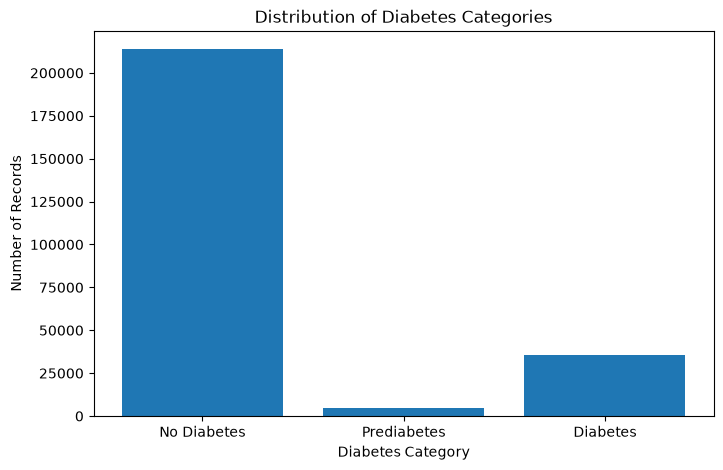

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(target_distribution['Class'],
        target_distribution['Count'])

plt.title("Distribution of Diabetes Categories")
plt.xlabel("Diabetes Category")
plt.ylabel("Number of Records")

plt.show()

## Part-2 Exploratory Data Analysis

In [14]:
# Display all feature names with their data types

feature_summary = pd.DataFrame({
    'Feature': df.columns,
    'Data Type': df.dtypes.values,
    'Unique Values': [df[col].nunique() for col in df.columns]
})

print(feature_summary.to_string(index=False))

             Feature Data Type  Unique Values
        Diabetes_012   float64              3
              HighBP   float64              2
            HighChol   float64              2
           CholCheck   float64              2
                 BMI   float64             84
              Smoker   float64              2
              Stroke   float64              2
HeartDiseaseorAttack   float64              2
        PhysActivity   float64              2
              Fruits   float64              2
             Veggies   float64              2
   HvyAlcoholConsump   float64              2
       AnyHealthcare   float64              2
         NoDocbcCost   float64              2
             GenHlth   float64              5
            MentHlth   float64             31
            PhysHlth   float64             31
            DiffWalk   float64              2
                 Sex   float64              2
                 Age   float64             13
           Education   float64    

In [15]:
# Summary statistics for selected numerical features

numerical_features = [
    'BMI',
    'GenHlth',
    'MentHlth',
    'PhysHlth',
    'Age',
    'Education',
    'Income'
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
GenHlth,253680.0,2.511392,1.068477,1.0,2.0,2.0,3.0,5.0
MentHlth,253680.0,3.184772,7.412847,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.242081,8.717951,0.0,0.0,0.0,3.0,30.0
Age,253680.0,8.032119,3.054220,1.0,6.0,8.0,10.0,13.0
Education,253680.0,5.050434,0.985774,1.0,4.0,5.0,6.0,6.0
Income,253680.0,6.053875,2.071148,1.0,5.0,7.0,8.0,8.0


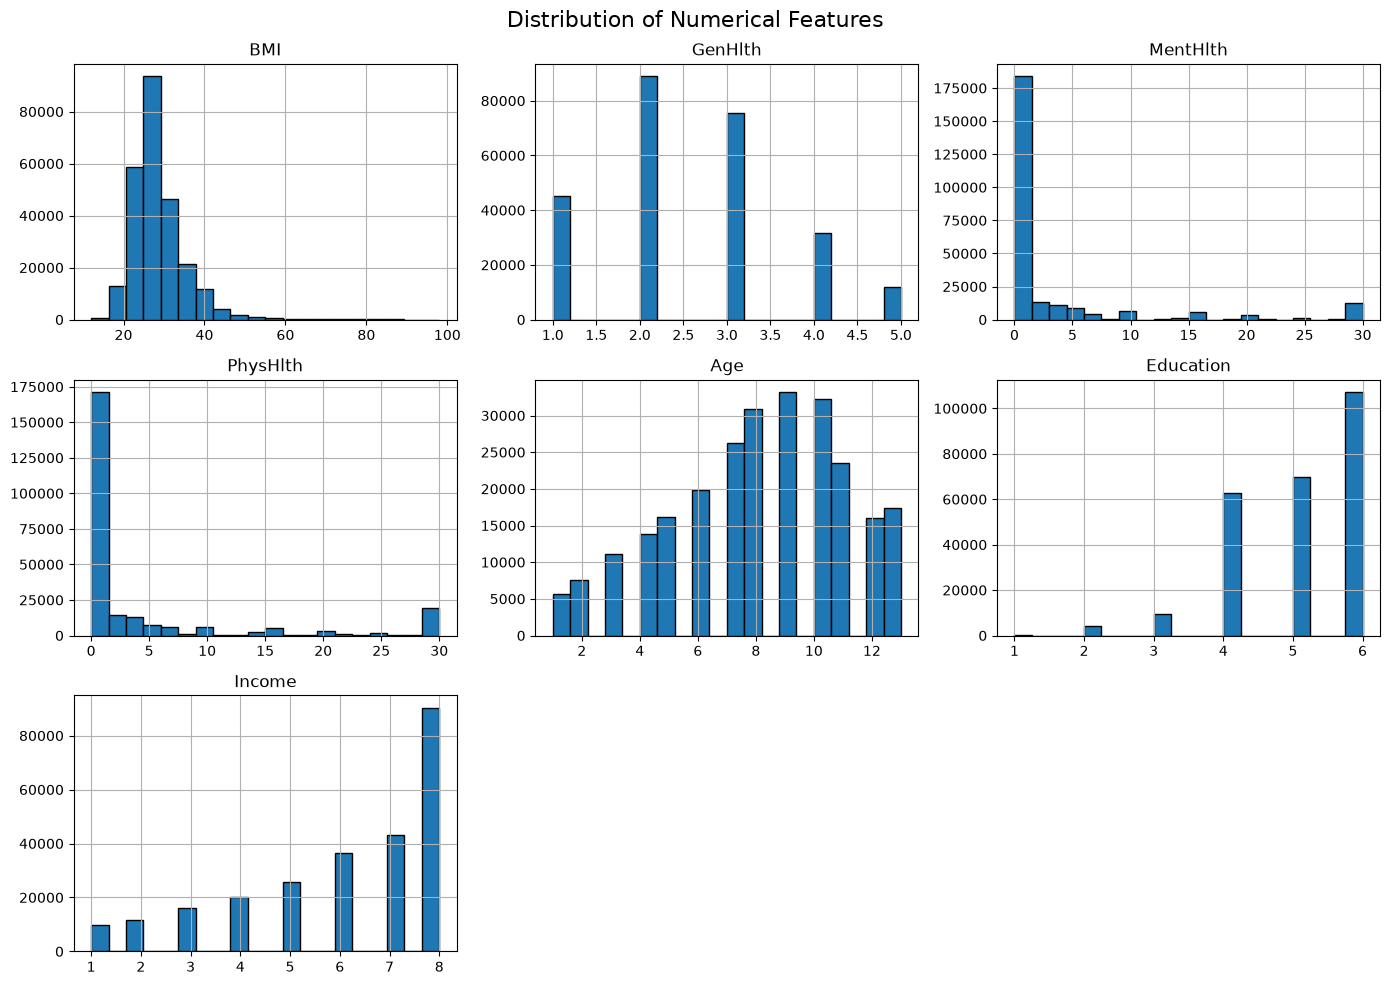

In [16]:
# Plot distributions of numerical features

numerical_features = [
    'BMI',
    'GenHlth',
    'MentHlth',
    'PhysHlth',
    'Age',
    'Education',
    'Income'
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

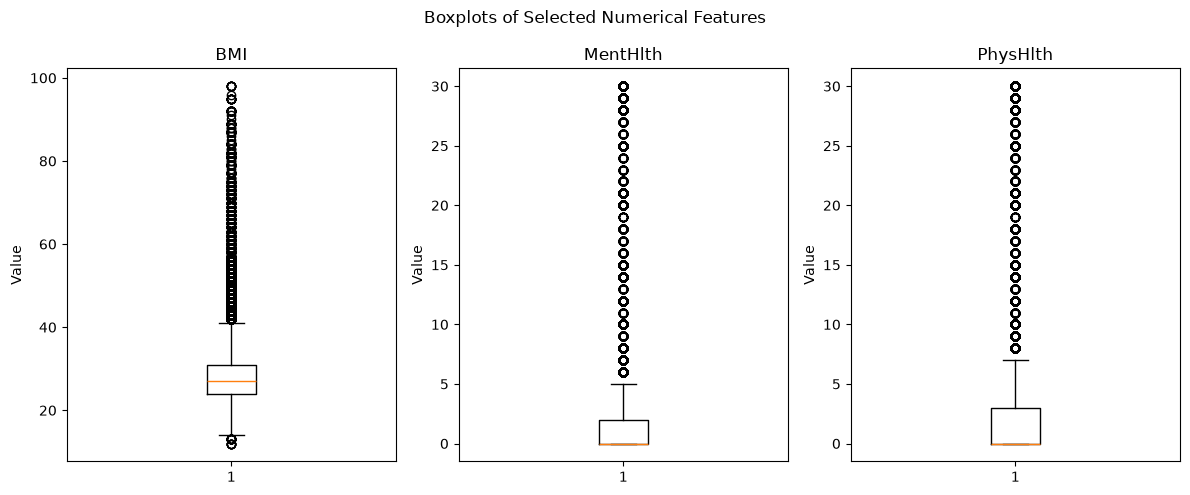

In [17]:
# Create boxplots to identify potential outliers

numerical_features = [
    'BMI',
    'MentHlth',
    'PhysHlth'
]

plt.figure(figsize=(12, 5))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(1, 3, i)
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel('Value')

plt.suptitle("Boxplots of Selected Numerical Features")
plt.tight_layout()
plt.show()

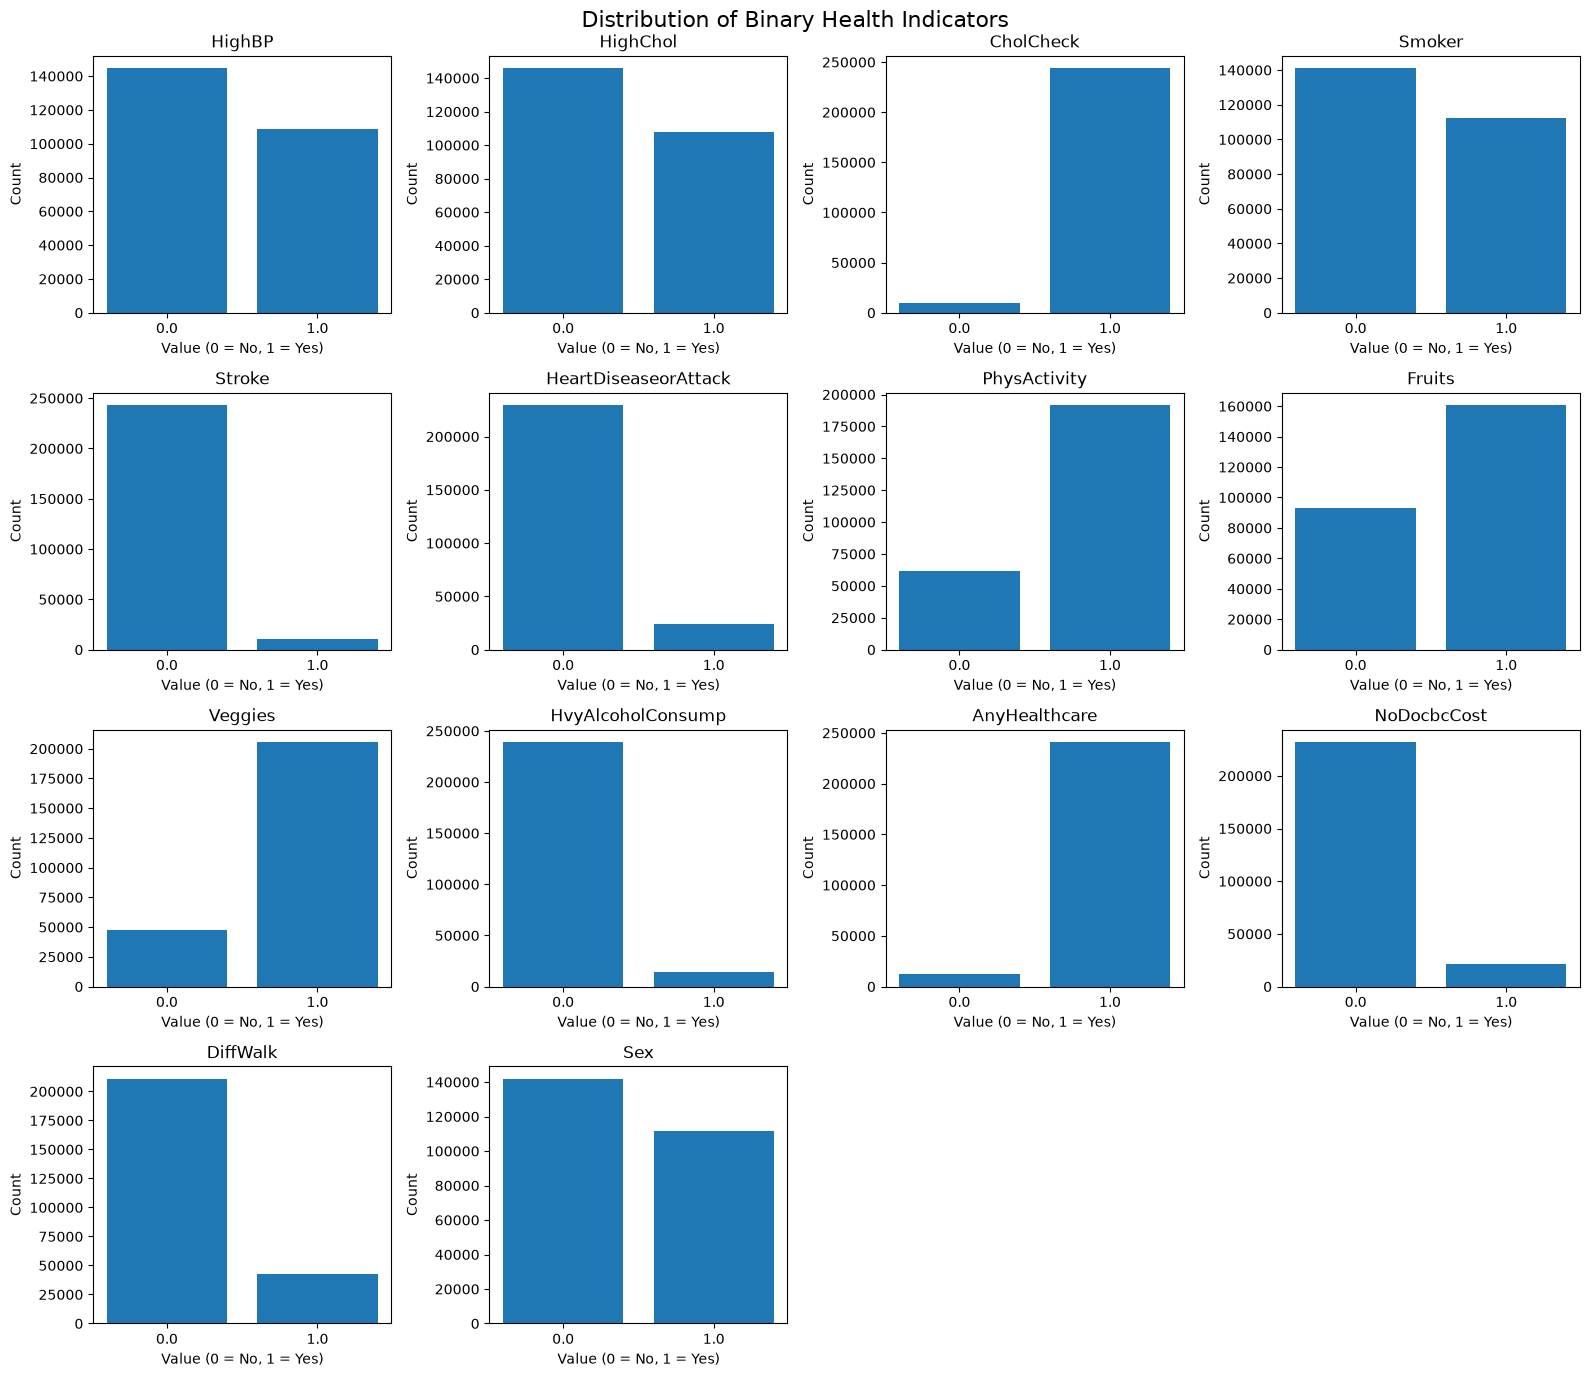

In [18]:
binary_features = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker',
    'Stroke', 'HeartDiseaseorAttack', 'PhysActivity',
    'Fruits', 'Veggies', 'HvyAlcoholConsump',
    'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(binary_features):
    counts = df[col].value_counts().sort_index()

    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(col)
    axes[i].set_xlabel('Value (0 = No, 1 = Yes)')
    axes[i].set_ylabel('Count')

for j in range(len(binary_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribution of Binary Health Indicators", fontsize=16)
plt.tight_layout()
plt.show()

In [19]:
# Calculate average values of selected features for each diabetes class

selected_features = [
    'BMI', 'HighBP', 'HighChol',
    'GenHlth', 'PhysHlth', 'MentHlth',
    'PhysActivity', 'Age'
]

class_comparison = df.groupby('Diabetes_012')[selected_features].mean().T

class_comparison.columns = [
    'No Diabetes',
    'Prediabetes',
    'Diabetes'
]

print(class_comparison.round(2))

              No Diabetes  Prediabetes  Diabetes
BMI                 27.74        30.72     31.94
HighBP               0.37         0.63      0.75
HighChol             0.38         0.62      0.67
GenHlth              2.37         2.98      3.29
PhysHlth             3.58         6.35      7.95
MentHlth             2.94         4.53      4.46
PhysActivity         0.78         0.68      0.63
Age                  7.79         9.08      9.38


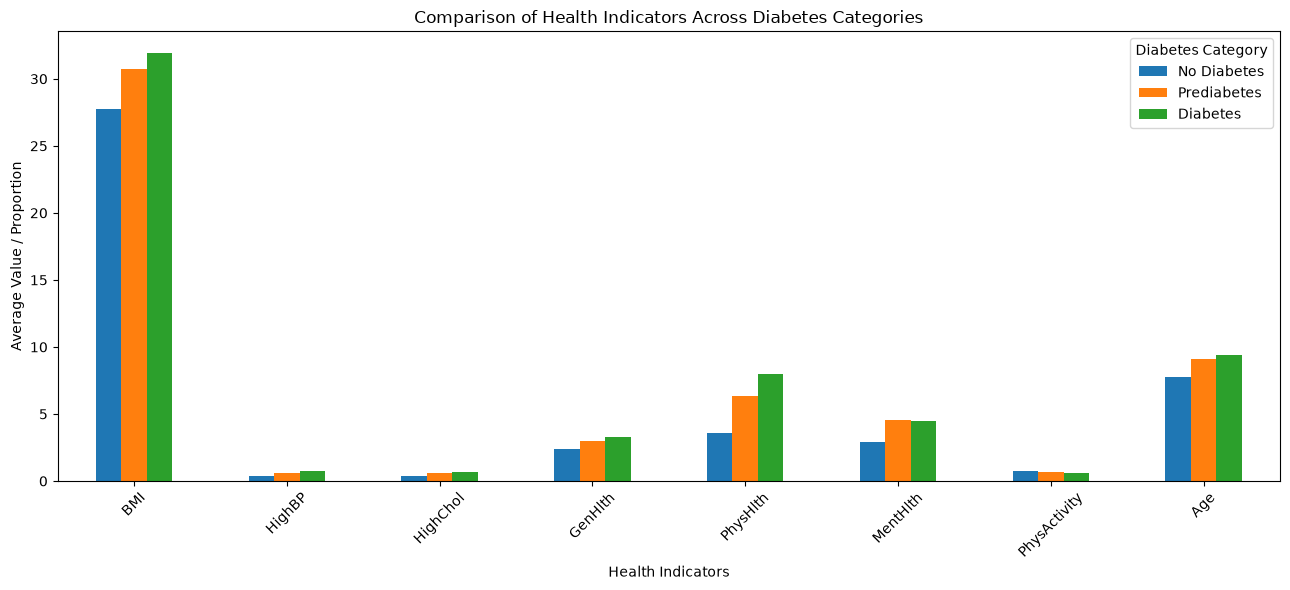

In [20]:
class_comparison.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title("Comparison of Health Indicators Across Diabetes Categories")
plt.xlabel("Health Indicators")
plt.ylabel("Average Value / Proportion")
plt.xticks(rotation=45)
plt.legend(title="Diabetes Category")
plt.tight_layout()
plt.show()

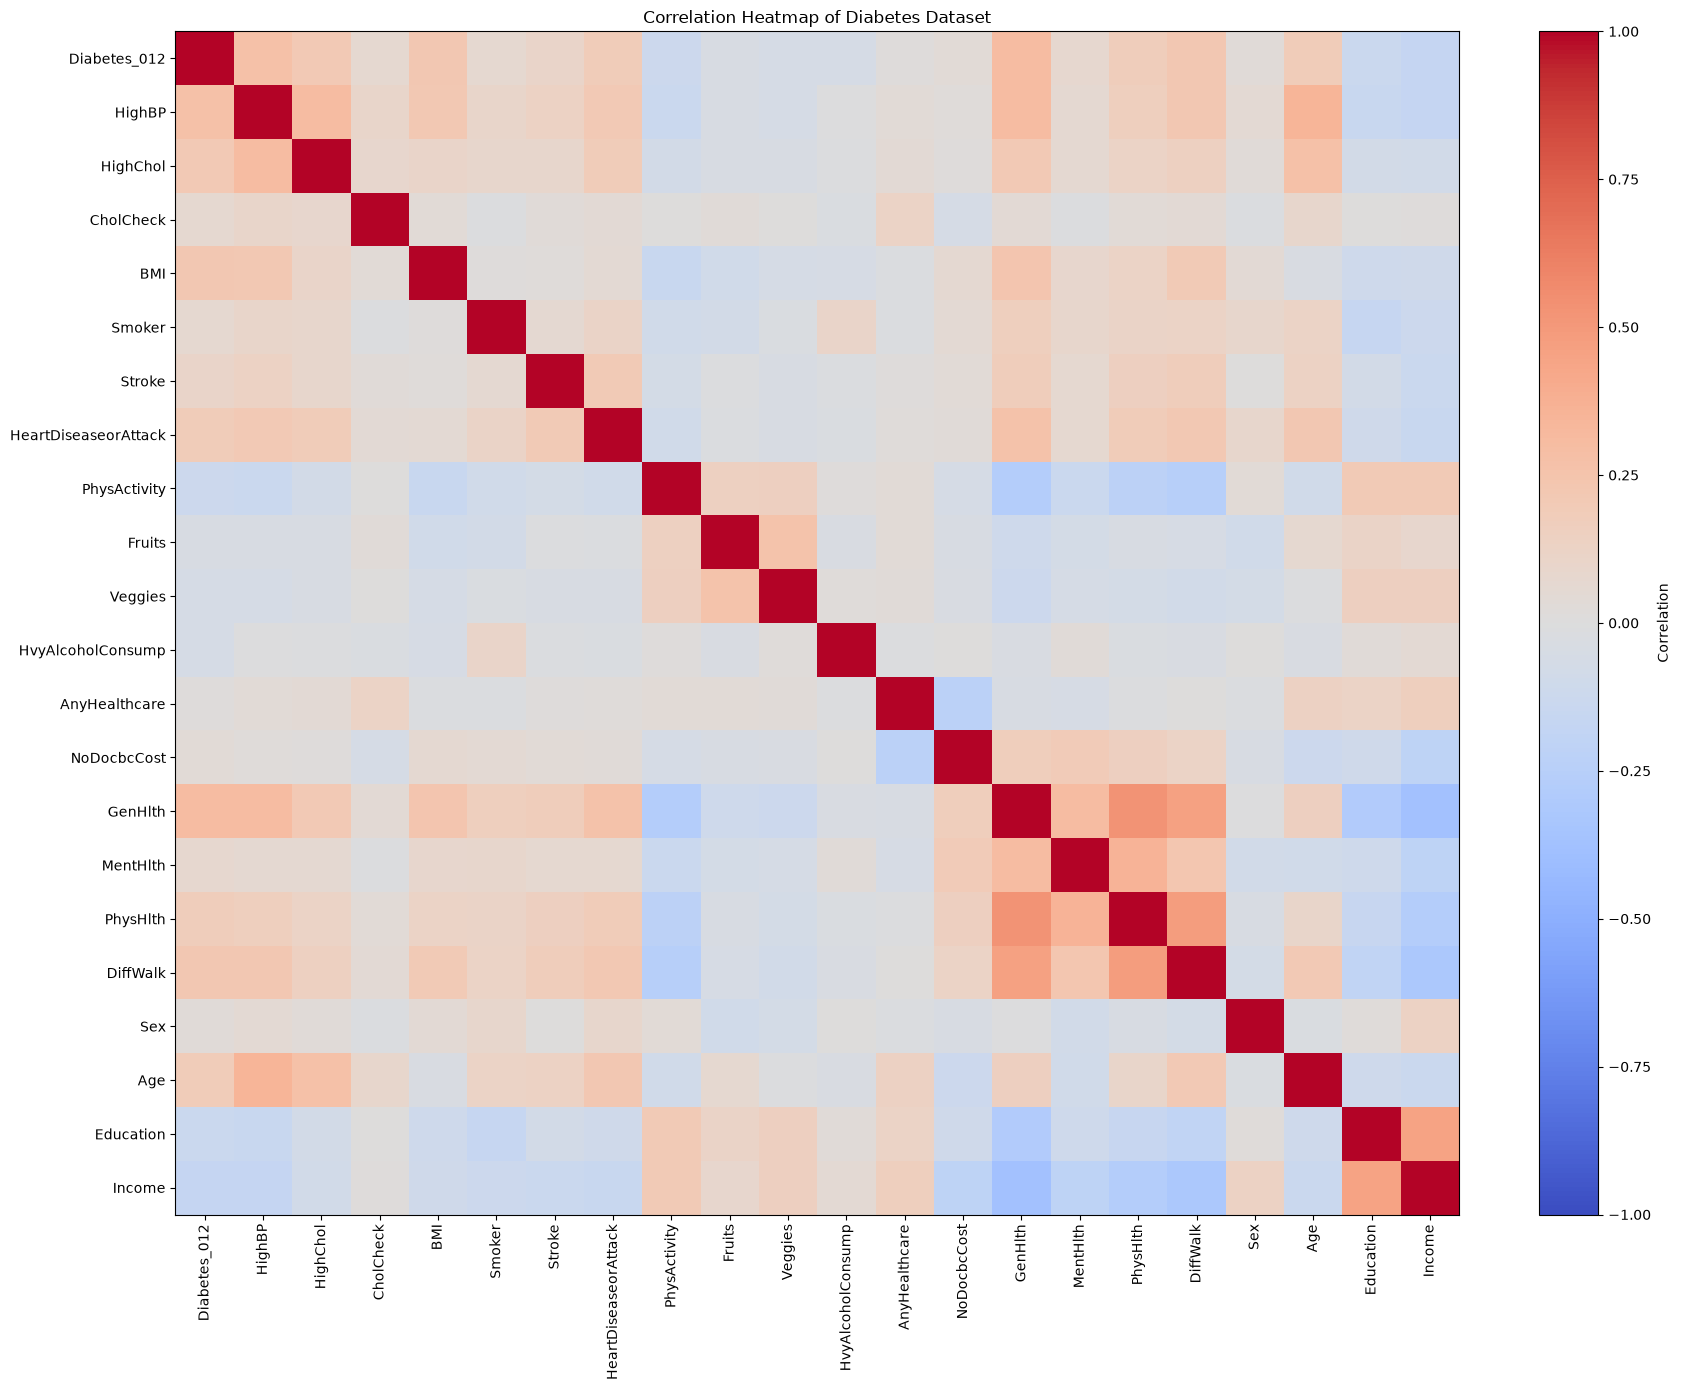

In [21]:
correlation_matrix = df.corr()

plt.figure(figsize=(18, 14))

plt.imshow(correlation_matrix, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.tight_layout()
plt.show()

In [22]:
target_correlation = (
    correlation_matrix['Diabetes_012']
    .drop('Diabetes_012')
    .sort_values(key=abs, ascending=False)
)

print("Feature correlation with Diabetes_012:")
print(target_correlation.round(4))

Feature correlation with Diabetes_012:
GenHlth                 0.3026
HighBP                  0.2716
BMI                     0.2244
DiffWalk                0.2242
HighChol                0.2091
Age                     0.1850
HeartDiseaseorAttack    0.1803
PhysHlth                0.1763
Income                 -0.1715
Education              -0.1305
PhysActivity           -0.1219
Stroke                  0.1072
MentHlth                0.0735
CholCheck               0.0675
Smoker                  0.0629
Veggies                -0.0590
HvyAlcoholConsump      -0.0579
Fruits                 -0.0422
NoDocbcCost             0.0354
Sex                     0.0310
AnyHealthcare           0.0154
Name: Diabetes_012, dtype: float64


## Part-3 Data preprocessing and preparation

In [23]:
# Separate independent variables (X) and dependent variable (y)

X = df.drop(columns=['Diabetes_012'])
y = df['Diabetes_012']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (253680, 21)
Target variable shape: (253680,)


In [24]:
# Display class counts and percentages

class_distribution = pd.DataFrame({
    'Count': y.value_counts().sort_index(),
    'Percentage': y.value_counts(normalize=True).sort_index() * 100
})

class_distribution.index = [
    'No Diabetes',
    'Prediabetes',
    'Diabetes'
]

print(class_distribution.round(2))

              Count  Percentage
No Diabetes  213703       84.24
Prediabetes    4631        1.83
Diabetes      35346       13.93


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (177576, 21)
Testing features: (76104, 21)
Training target: (177576,)
Testing target: (76104,)


In [26]:
# Compare class proportions in original, training and testing data

split_distribution = pd.DataFrame({
    'Original (%)': y.value_counts(normalize=True).sort_index() * 100,
    'Training (%)': y_train.value_counts(normalize=True).sort_index() * 100,
    'Testing (%)': y_test.value_counts(normalize=True).sort_index() * 100
})

split_distribution.index = [
    'No Diabetes',
    'Prediabetes',
    'Diabetes'
]

print(split_distribution.round(2))

             Original (%)  Training (%)  Testing (%)
No Diabetes         84.24         84.24        84.24
Prediabetes          1.83          1.83         1.83
Diabetes            13.93         13.93        13.93


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (177576, 21)
Scaled testing data shape: (76104, 21)


In [28]:
from sklearn.model_selection import GroupShuffleSplit

# Assign the same group ID to identical predictor combinations
groups = pd.factorize(pd.MultiIndex.from_frame(X))[0]

print("Total unique predictor groups:", len(np.unique(groups)))
print("Total observations:", len(groups))

Total unique predictor groups: 227908
Total observations: 253680


In [29]:
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

print("Group-aware training shape:", X_train_group.shape)
print("Group-aware testing shape:", X_test_group.shape)

Group-aware training shape: (177254, 21)
Group-aware testing shape: (76426, 21)


In [30]:
train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

overlapping_groups = train_groups.intersection(test_groups)

print("Overlapping predictor groups:", len(overlapping_groups))

if len(overlapping_groups) == 0:
    print("Success: No identical predictor combinations appear in both sets.")
else:
    print("Warning: Some predictor groups overlap.")

Overlapping predictor groups: 0
Success: No identical predictor combinations appear in both sets.


In [31]:
group_distribution = pd.DataFrame({
    'Original (%)': y.value_counts(normalize=True).sort_index() * 100,
    'Group Training (%)': y_train_group.value_counts(normalize=True).sort_index() * 100,
    'Group Testing (%)': y_test_group.value_counts(normalize=True).sort_index() * 100
})

group_distribution.index = [
    'No Diabetes',
    'Prediabetes',
    'Diabetes'
]

print(group_distribution.round(2))

             Original (%)  Group Training (%)  Group Testing (%)
No Diabetes         84.24               84.20              84.35
Prediabetes          1.83                1.85               1.78
Diabetes            13.93               13.96              13.87


## Part-4 Handling Class Imbalance

In [32]:
# Check class counts in group-aware training data

print("Training class distribution:")
print(y_train_group.value_counts().sort_index())

print("\nTraining class percentages:")
print(
    (y_train_group.value_counts(normalize=True).sort_index() * 100).round(2)
)

Training class distribution:
Diabetes_012
0.0    149241
1.0      3271
2.0     24742
Name: count, dtype: int64

Training class percentages:
Diabetes_012
0.0    84.20
1.0     1.85
2.0    13.96
Name: proportion, dtype: float64


In [33]:
%pip install imbalanced-learn

  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached imbalanced_learn-0.14.2-py3-none-any.whl (236 kB)
Using cached sklearn_compat-0.1.6-py3-none-any.whl (22 kB)

   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from collections import Counter

print("Imbalanced-learn imported successfully!")

Imbalanced-learn imported successfully!


In [35]:
# Randomly increase minority class observations

ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_group,
    y_train_group
)

print("Before oversampling:", Counter(y_train_group))
print("After oversampling:", Counter(y_train_ros))

Before oversampling: Counter({0.0: 149241, 2.0: 24742, 1.0: 3271})
After oversampling: Counter({0.0: 149241, 2.0: 149241, 1.0: 149241})


In [36]:
# Generate synthetic minority class observations

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_group,
    y_train_group
)

print("Before SMOTE:", Counter(y_train_group))
print("After SMOTE:", Counter(y_train_smote))

Before SMOTE: Counter({0.0: 149241, 2.0: 24742, 1.0: 3271})
After SMOTE: Counter({0.0: 149241, 2.0: 149241, 1.0: 149241})


In [37]:
# Compare class distributions before and after resampling

comparison = pd.DataFrame({
    'Original Training': y_train_group.value_counts().sort_index(),
    'Random Oversampling': y_train_ros.value_counts().sort_index(),
    'SMOTE': y_train_smote.value_counts().sort_index()
})

comparison.index = ['No Diabetes', 'Prediabetes', 'Diabetes']

print(comparison)

             Original Training  Random Oversampling   SMOTE
No Diabetes             149241               149241  149241
Prediabetes               3271               149241  149241
Diabetes                 24742               149241  149241


## Part-5 Data for model training

In [38]:
from sklearn.preprocessing import StandardScaler

# Scale features for Logistic Regression
scaler_group = StandardScaler()

X_train_group_scaled = scaler_group.fit_transform(X_train_group)
X_test_group_scaled = scaler_group.transform(X_test_group)

print("Training data:", X_train_group.shape)
print("Testing data:", X_test_group.shape)
print("Data preparation completed!")

Training data: (177254, 21)
Testing data: (76426, 21)
Data preparation completed!


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Models and evaluation metrics imported successfully!")

Models and evaluation metrics imported successfully!


In [40]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Logistic Regression (Balanced)': LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Decision Tree (Balanced)': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'Random Forest (Balanced)': RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    if 'Logistic Regression' in name:
        X_tr = X_train_group_scaled
        X_te = X_test_group_scaled
    else:
        X_tr = X_train_group
        X_te = X_test_group

    print("\nTraining:", name)

    model.fit(X_tr, y_train_group)

    y_pred = model.predict(X_te)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_group, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test_group, y_pred),
        'Macro F1': f1_score(y_test_group, y_pred, average='macro'),
        'Weighted F1': f1_score(y_test_group, y_pred, average='weighted')
    })

print("\nAll six models trained successfully!")


Training: Logistic Regression

Training: Logistic Regression (Balanced)

Training: Decision Tree

Training: Decision Tree (Balanced)

Training: Random Forest

Training: Random Forest (Balanced)

All six models trained successfully!


In [41]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                            Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
0  Logistic Regression (Balanced)    0.6470             0.5255    0.4285       0.7223
1                   Decision Tree    0.7690             0.4070    0.4037       0.7747
2                   Random Forest    0.8453             0.3871    0.3971       0.8096
3        Decision Tree (Balanced)    0.7630             0.3976    0.3950       0.7694
4             Logistic Regression    0.8466             0.3826    0.3914       0.8081
5        Random Forest (Balanced)    0.8448             0.3783    0.3858       0.8048


In [42]:
for name, model in models.items():

    if 'Logistic Regression' in name:
        X_te = X_test_group_scaled
    else:
        X_te = X_test_group

    y_pred = model.predict(X_te)

    print("\n", "=" * 65)
    print(name)
    print("=" * 65)

    print(classification_report(
        y_test_group,
        y_pred,
        labels=[0, 1, 2],
        target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

 No Diabetes       0.86      0.98      0.92     64462
 Prediabetes       0.00      0.00      0.00      1360
    Diabetes       0.52      0.17      0.26     10604

    accuracy                           0.85     76426
   macro avg       0.46      0.38      0.39     76426
weighted avg       0.80      0.85      0.81     76426


Logistic Regression (Balanced)
              precision    recall  f1-score   support

 No Diabetes       0.95      0.66      0.78     64462
 Prediabetes       0.03      0.32      0.06      1360
    Diabetes       0.36      0.59      0.45     10604

    accuracy                           0.65     76426
   macro avg       0.45      0.53      0.43     76426
weighted avg       0.85      0.65      0.72     76426


Decision Tree
              precision    recall  f1-score   support

 No Diabetes       0.88      0.86      0.87     64462
 Prediabetes       0.03      0.04      0.04      1360
    Dia

In [43]:
# Use the scaler fitted on the original training data

X_train_ros_scaled = scaler_group.transform(X_train_ros)

print("Oversampled training shape:", X_train_ros.shape)
print("Scaled oversampled shape:", X_train_ros_scaled.shape)

Oversampled training shape: (447723, 21)
Scaled oversampled shape: (447723, 21)


In [44]:
ros_models = {
    'Logistic Regression (ROS)': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree (ROS)': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest (ROS)': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

ros_results = []

for name, model in ros_models.items():

    if 'Logistic Regression' in name:
        X_tr = X_train_ros_scaled
        X_te = X_test_group_scaled
    else:
        X_tr = X_train_ros
        X_te = X_test_group

    print("\nTraining:", name)

    model.fit(X_tr, y_train_ros)

    y_pred = model.predict(X_te)

    ros_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_group, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test_group, y_pred),
        'Macro F1': f1_score(y_test_group, y_pred, average='macro'),
        'Weighted F1': f1_score(y_test_group, y_pred, average='weighted')
    })

print("\nRandom Oversampling experiments completed!")


Training: Logistic Regression (ROS)

Training: Decision Tree (ROS)

Training: Random Forest (ROS)

Random Oversampling experiments completed!


In [45]:
ros_results_df = pd.DataFrame(ros_results)

print(
    ros_results_df.sort_values(
        by='Macro F1',
        ascending=False
    ).round(4)
)

                       Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
0  Logistic Regression (ROS)    0.6468             0.5251    0.4282       0.7220
2        Random Forest (ROS)    0.8305             0.4197    0.4269       0.8143
1        Decision Tree (ROS)    0.7640             0.3968    0.3943       0.7694


In [46]:
for name, model in ros_models.items():

    if 'Logistic Regression' in name:
        X_te = X_test_group_scaled
    else:
        X_te = X_test_group

    y_pred = model.predict(X_te)

    print("\n", "=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test_group,
        y_pred,
        labels=[0, 1, 2],
        target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
        zero_division=0
    ))


Logistic Regression (ROS)
              precision    recall  f1-score   support

 No Diabetes       0.95      0.66      0.78     64462
 Prediabetes       0.03      0.32      0.06      1360
    Diabetes       0.36      0.59      0.45     10604

    accuracy                           0.65     76426
   macro avg       0.45      0.53      0.43     76426
weighted avg       0.85      0.65      0.72     76426


Decision Tree (ROS)
              precision    recall  f1-score   support

 No Diabetes       0.87      0.86      0.86     64462
 Prediabetes       0.03      0.04      0.03      1360
    Diabetes       0.28      0.30      0.29     10604

    accuracy                           0.76     76426
   macro avg       0.39      0.40      0.39     76426
weighted avg       0.78      0.76      0.77     76426


Random Forest (ROS)
              precision    recall  f1-score   support

 No Diabetes       0.88      0.93      0.90     64462
 Prediabetes       0.04      0.00      0.01      1360
    Di

In [47]:
categorical_features = [
    'HighBP',
    'HighChol',
    'CholCheck',
    'Smoker',
    'Stroke',
    'HeartDiseaseorAttack',
    'PhysActivity',
    'Fruits',
    'Veggies',
    'HvyAlcoholConsump',
    'AnyHealthcare',
    'NoDocbcCost',
    'GenHlth',
    'DiffWalk',
    'Sex',
    'Age',
    'Education',
    'Income'
]

categorical_indices = [
    X_train_group.columns.get_loc(col)
    for col in categorical_features
]

print("Number of categorical features:", len(categorical_indices))
print("Number of numerical features:", X_train_group.shape[1] - len(categorical_indices))

Number of categorical features: 18
Number of numerical features: 3


In [48]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train_group,
    y_train_group
)

print("Before SMOTENC:", Counter(y_train_group))
print("After SMOTENC:", Counter(y_train_smotenc))

Before SMOTENC: Counter({0.0: 149241, 2.0: 24742, 1.0: 3271})
After SMOTENC: Counter({0.0: 149241, 2.0: 149241, 1.0: 149241})


In [49]:
for col in categorical_features:
    print(
        col,
        "Unique values:",
        sorted(X_train_smotenc[col].unique())
    )

HighBP Unique values: [np.float64(0.0), np.float64(1.0)]
HighChol Unique values: [np.float64(0.0), np.float64(1.0)]
CholCheck Unique values: [np.float64(0.0), np.float64(1.0)]
Smoker Unique values: [np.float64(0.0), np.float64(1.0)]
Stroke Unique values: [np.float64(0.0), np.float64(1.0)]
HeartDiseaseorAttack Unique values: [np.float64(0.0), np.float64(1.0)]
PhysActivity Unique values: [np.float64(0.0), np.float64(1.0)]
Fruits Unique values: [np.float64(0.0), np.float64(1.0)]
Veggies Unique values: [np.float64(0.0), np.float64(1.0)]
HvyAlcoholConsump Unique values: [np.float64(0.0), np.float64(1.0)]
AnyHealthcare Unique values: [np.float64(0.0), np.float64(1.0)]
NoDocbcCost Unique values: [np.float64(0.0), np.float64(1.0)]
GenHlth Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
DiffWalk Unique values: [np.float64(0.0), np.float64(1.0)]
Sex Unique values: [np.float64(0.0), np.float64(1.0)]
Age Unique values: [np.float64(1.0), np.float

In [50]:
X_train_smotenc_scaled = scaler_group.transform(X_train_smotenc)

print("SMOTENC training data:", X_train_smotenc.shape)
print("Scaled SMOTENC data:", X_train_smotenc_scaled.shape)

SMOTENC training data: (447723, 21)
Scaled SMOTENC data: (447723, 21)


In [51]:
smotenc_models = {
    'Logistic Regression (SMOTENC)': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Random Forest (SMOTENC)': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

smotenc_results = []

for name, model in smotenc_models.items():

    if 'Logistic Regression' in name:
        X_tr = X_train_smotenc_scaled
        X_te = X_test_group_scaled
    else:
        X_tr = X_train_smotenc
        X_te = X_test_group

    print("\nTraining:", name)

    model.fit(X_tr, y_train_smotenc)

    y_pred = model.predict(X_te)

    smotenc_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_group, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test_group, y_pred),
        'Macro F1': f1_score(y_test_group, y_pred, average='macro'),
        'Weighted F1': f1_score(y_test_group, y_pred, average='weighted')
    })

print("\nSMOTENC experiments completed!")


Training: Logistic Regression (SMOTENC)

Training: Random Forest (SMOTENC)

SMOTENC experiments completed!


In [52]:
for name, model in smotenc_models.items():

    if 'Logistic Regression' in name:
        X_te = X_test_group_scaled
    else:
        X_te = X_test_group

    y_pred = model.predict(X_te)

    print("\n", "=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test_group,
        y_pred,
        labels=[0, 1, 2],
        target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
        zero_division=0
    ))


Logistic Regression (SMOTENC)
              precision    recall  f1-score   support

 No Diabetes       0.94      0.66      0.78     64462
 Prediabetes       0.03      0.32      0.05      1360
    Diabetes       0.38      0.52      0.44     10604

    accuracy                           0.63     76426
   macro avg       0.45      0.50      0.42     76426
weighted avg       0.85      0.63      0.72     76426


Random Forest (SMOTENC)
              precision    recall  f1-score   support

 No Diabetes       0.90      0.86      0.88     64462
 Prediabetes       0.02      0.02      0.02      1360
    Diabetes       0.37      0.45      0.41     10604

    accuracy                           0.79     76426
   macro avg       0.43      0.45      0.44     76426
weighted avg       0.81      0.79      0.80     76426



In [53]:
smotenc_results_df = pd.DataFrame(smotenc_results).sort_values(
    by='Macro F1',
    ascending=False
)

display(smotenc_results_df.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
1,Random Forest (SMOTENC),0.7900,0.4455,0.4357,0.7981
0,Logistic Regression (SMOTENC),0.6342,0.4978,0.4202,0.7168


In [54]:
combined_results = pd.concat(
    [ros_results_df, smotenc_results_df],
    ignore_index=True
)

combined_results = combined_results.sort_values(
    by='Macro F1',
    ascending=False
)

print("Comparison of ROS and SMOTENC Models:")
display(combined_results.round(4))

Comparison of ROS and SMOTENC Models:


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
3,Random Forest (SMOTENC),0.7900,0.4455,0.4357,0.7981
0,Logistic Regression (ROS),0.6468,0.5251,0.4282,0.7220
2,Random Forest (ROS),0.8305,0.4197,0.4269,0.8143
4,Logistic Regression (SMOTENC),0.6342,0.4978,0.4202,0.7168
1,Decision Tree (ROS),0.7640,0.3968,0.3943,0.7694


In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


 Logistic Regression (ROS)
[[42722 11079 10661]
 [  361   437   562]
 [ 1798  2536  6270]]


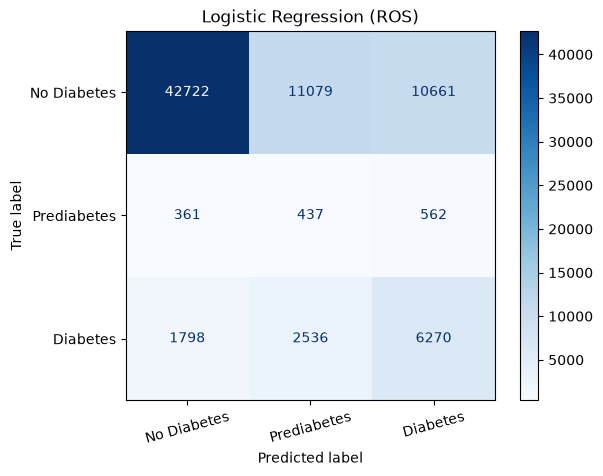

c:\Users\gpala\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



 Random Forest (ROS)
[[64462     0     0]
 [ 1360     0     0]
 [10604     0     0]]


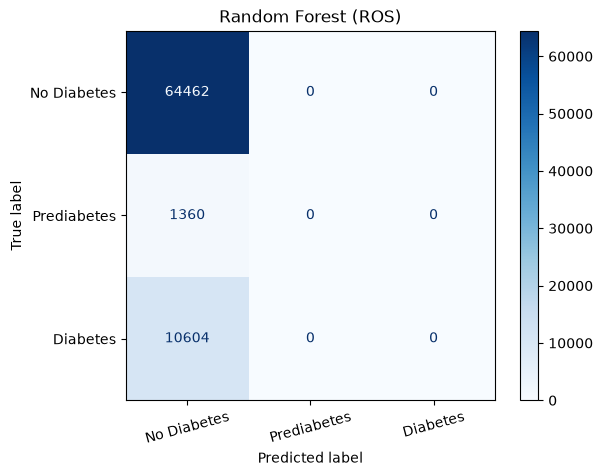

c:\Users\gpala\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



 Random Forest (SMOTENC)
[[64462     0     0]
 [ 1360     0     0]
 [10604     0     0]]


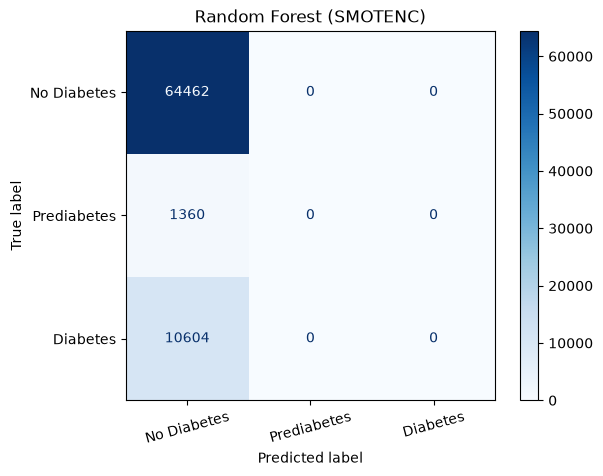

In [56]:
# Selected leading models
selected_models = {
    'Logistic Regression (ROS)': ros_models['Logistic Regression (ROS)'],
    'Random Forest (ROS)': ros_models['Random Forest (ROS)'],
    'Random Forest (SMOTENC)': smotenc_models['Random Forest (SMOTENC)']
}

for name, model in selected_models.items():

    y_pred = model.predict(X_test_group_scaled)

    cm = confusion_matrix(
        y_test_group,
        y_pred,
        labels=[0, 1, 2]
    )

    print("\n", name)
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Diabetes', 'Prediabetes', 'Diabetes']
    )

    disp.plot(cmap='Blues', values_format='d')
    plt.title(name)
    plt.xticks(rotation=15)
    plt.show()

In [57]:
class_comparison = []

for name, model in selected_models.items():

    y_pred = model.predict(X_test_group_scaled)

    report = classification_report(
        y_test_group,
        y_pred,
        labels=[0, 1, 2],
        target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
        output_dict=True,
        zero_division=0
    )

    for class_name in ['No Diabetes', 'Prediabetes', 'Diabetes']:

        class_comparison.append({
            'Model': name,
            'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1 Score': report[class_name]['f1-score']
        })

class_comparison_df = pd.DataFrame(class_comparison)

display(class_comparison_df.round(4))

c:\Users\gpala\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\gpala\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


,Model,Class,Precision,Recall,F1 Score
0,Logistic Regression (ROS),No Diabetes,0.9519,0.6627,0.7814
1,Logistic Regression (ROS),Prediabetes,0.0311,0.3213,0.0567
2,Logistic Regression (ROS),Diabetes,0.3584,0.5913,0.4463
3,Random Forest (ROS),No Diabetes,0.8435,1.0000,0.9151
4,Random Forest (ROS),Prediabetes,0.0000,0.0000,0.0000
5,Random Forest (ROS),Diabetes,0.0000,0.0000,0.0000
6,Random Forest (SMOTENC),No Diabetes,0.8435,1.0000,0.9151
7,Random Forest (SMOTENC),Prediabetes,0.0000,0.0000,0.0000
8,Random Forest (SMOTENC),Diabetes,0.0000,0.0000,0.0000


In [58]:
# Random Forest with Random Oversampling
rf_ros_corrected = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_ros_corrected.fit(X_train_ros, y_train_ros)


# Random Forest with SMOTENC
rf_smotenc_corrected = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smotenc_corrected.fit(X_train_smotenc, y_train_smotenc)

print("Both Random Forest models retrained successfully!")

Both Random Forest models retrained successfully!


In [59]:
corrected_rf_models = {
    'Random Forest (ROS)': rf_ros_corrected,
    'Random Forest (SMOTENC)': rf_smotenc_corrected
}

corrected_rf_results = []

for name, model in corrected_rf_models.items():

    y_pred = model.predict(X_test_group)

    corrected_rf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_group, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test_group, y_pred),
        'Macro F1': f1_score(y_test_group, y_pred, average='macro'),
        'Weighted F1': f1_score(y_test_group, y_pred, average='weighted')
    })

display(pd.DataFrame(corrected_rf_results).round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest (ROS),0.8305,0.4197,0.4269,0.8143
1,Random Forest (SMOTENC),0.7900,0.4455,0.4357,0.7981


In [60]:
for name, model in corrected_rf_models.items():

    y_pred = model.predict(X_test_group)

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test_group,
        y_pred,
        labels=[0, 1, 2],
        target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test_group,
        y_pred,
        labels=[0, 1, 2]
    ))


Random Forest (ROS)
              precision    recall  f1-score   support

 No Diabetes       0.88      0.93      0.90     64462
 Prediabetes       0.04      0.00      0.01      1360
    Diabetes       0.43      0.32      0.37     10604

    accuracy                           0.83     76426
   macro avg       0.45      0.42      0.43     76426
weighted avg       0.80      0.83      0.81     76426

Confusion Matrix:
[[60036    99  4327]
 [ 1084     6   270]
 [ 7140    36  3428]]

Random Forest (SMOTENC)
              precision    recall  f1-score   support

 No Diabetes       0.90      0.86      0.88     64462
 Prediabetes       0.02      0.02      0.02      1360
    Diabetes       0.37      0.45      0.41     10604

    accuracy                           0.79     76426
   macro avg       0.43      0.45      0.44     76426
weighted avg       0.81      0.79      0.80     76426

Confusion Matrix:
[[55531  1199  7732]
 [  915    28   417]
 [ 5507   278  4819]]


In [61]:
feature_importance = pd.DataFrame({
    'Feature': X_train_group.columns,
    'Importance': rf_smotenc_corrected.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
3,BMI,0.2055
18,Age,0.1398
20,Income,0.0890
15,PhysHlth,0.0887
14,MentHlth,0.0708
13,GenHlth,0.0665
19,Education,0.0619
0,HighBP,0.0352
4,Smoker,0.0334
8,Fruits,0.0318


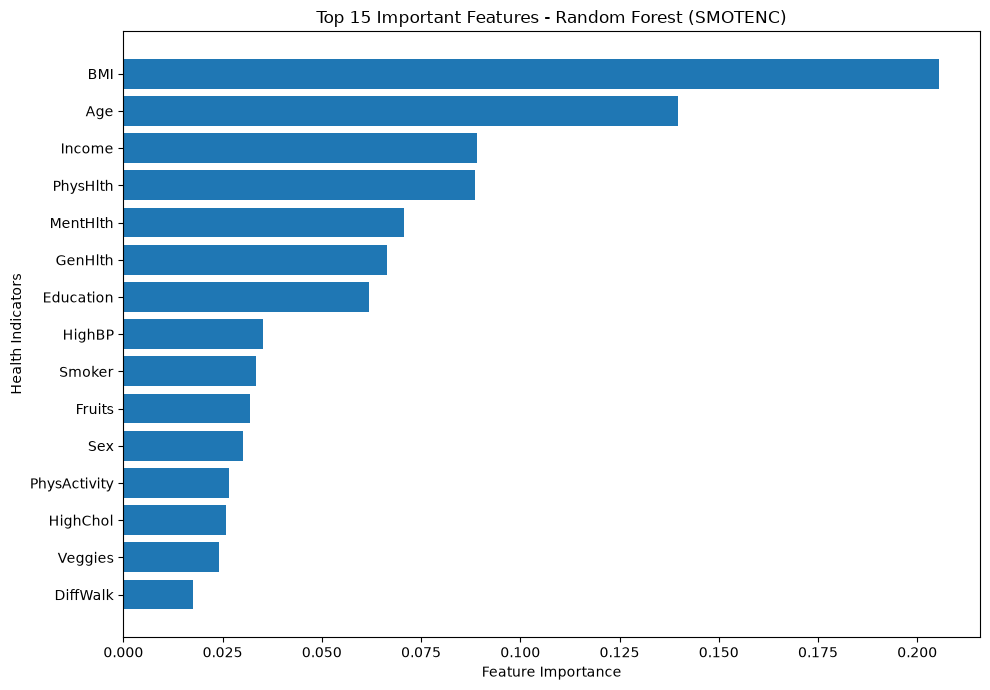

In [62]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Health Indicators')
plt.title('Top 15 Important Features - Random Forest (SMOTENC)')
plt.tight_layout()
plt.show()

In [63]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_smotenc_corrected,
    X_test_group,
    y_test_group,
    scoring='f1_macro',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': X_test_group.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by='Importance Mean',
    ascending=False
)

display(permutation_df.round(5))

,Feature,Importance Mean,Importance Std
13,GenHlth,0.02992,0.00128
3,BMI,0.02183,0.00161
0,HighBP,0.01667,0.00130
18,Age,0.01342,0.00119
1,HighChol,0.00609,0.00093
6,HeartDiseaseorAttack,0.00255,0.00054
10,HvyAlcoholConsump,0.00205,0.00054
2,CholCheck,0.00178,0.00054
16,DiffWalk,0.00098,0.00065
12,NoDocbcCost,0.00021,0.00013


In [64]:
X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train_group,
    y_train_group,
    test_size=0.20,
    random_state=42,
    stratify=y_train_group
)

print("Internal training shape:", X_subtrain.shape)
print("Validation shape:", X_validation.shape)

print("\nInternal training distribution:")
print(y_subtrain.value_counts().sort_index())

print("\nValidation distribution:")
print(y_validation.value_counts().sort_index())

Internal training shape: (141803, 21)
Validation shape: (35451, 21)

Internal training distribution:
Diabetes_012
0.0    119393
1.0      2617
2.0     19793
Name: count, dtype: int64

Validation distribution:
Diabetes_012
0.0    29848
1.0      654
2.0     4949
Name: count, dtype: int64


In [65]:
smotenc_validation = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_subtrain_resampled, y_subtrain_resampled = (
    smotenc_validation.fit_resample(X_subtrain, y_subtrain)
)

print("Resampled internal training shape:", X_subtrain_resampled.shape)

print("\nClass distribution:")
print(y_subtrain_resampled.value_counts().sort_index())

Resampled internal training shape: (358179, 21)

Class distribution:
Diabetes_012
0.0    119393
1.0    119393
2.0    119393
Name: count, dtype: int64


In [66]:
rf_validation = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_validation.fit(
    X_subtrain_resampled,
    y_subtrain_resampled
)

y_validation_pred = rf_validation.predict(X_validation)

print("Validation Accuracy:",
      accuracy_score(y_validation, y_validation_pred))

print("Validation Balanced Accuracy:",
      balanced_accuracy_score(y_validation, y_validation_pred))

print("Validation Macro F1:",
      f1_score(y_validation, y_validation_pred, average='macro'))

print("\nClassification Report:")
print(classification_report(
    y_validation,
    y_validation_pred,
    labels=[0, 1, 2],
    target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
    zero_division=0
))

Validation Accuracy: 0.7971284307917972
Validation Balanced Accuracy: 0.44702619896854384
Validation Macro F1: 0.43900547656809263

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.90      0.87      0.88     29848
 Prediabetes       0.02      0.02      0.02       654
    Diabetes       0.38      0.45      0.41      4949

    accuracy                           0.80     35451
   macro avg       0.43      0.45      0.44     35451
weighted avg       0.81      0.80      0.80     35451



In [67]:
validation_perm = permutation_importance(
    rf_validation,
    X_validation,
    y_validation,
    scoring='f1_macro',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

validation_importance_df = pd.DataFrame({
    'Feature': X_validation.columns,
    'Importance Mean': validation_perm.importances_mean,
    'Importance Std': validation_perm.importances_std
})

validation_importance_df = validation_importance_df.sort_values(
    by='Importance Mean',
    ascending=False
)

display(validation_importance_df.round(5))

,Feature,Importance Mean,Importance Std
13,GenHlth,0.03383,0.00068
3,BMI,0.02479,0.00072
0,HighBP,0.01976,0.00120
18,Age,0.01467,0.00148
1,HighChol,0.00967,0.00226
10,HvyAlcoholConsump,0.00347,0.00060
2,CholCheck,0.00217,0.00029
20,Income,0.00087,0.00336
16,DiffWalk,0.00063,0.00096
17,Sex,0.00052,0.00171


#### Feature Selection experiment

In [68]:
top_10_features = [
    'GenHlth', 'BMI', 'HighBP', 'Age', 'HighChol',
    'HvyAlcoholConsump', 'CholCheck', 'Income',
    'DiffWalk', 'Sex'
]

top_5_features = [
    'GenHlth', 'BMI', 'HighBP', 'Age', 'HighChol'
]

print("Full features:", X_subtrain.shape[1])
print("Top 10 features:", len(top_10_features))
print("Top 5 features:", len(top_5_features))

Full features: 21
Top 10 features: 10
Top 5 features: 5


In [69]:
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

feature_results = []

for name, features in [
    ('Top 10 Features', top_10_features),
    ('Top 5 Features', top_5_features)
]:

    X_train_selected = X_subtrain[features]
    X_val_selected = X_validation[features]

    selected_categorical = [
        col for col in categorical_features if col in features
    ]

    selected_cat_indices = [
        X_train_selected.columns.get_loc(col)
        for col in selected_categorical
    ]

    smote_selected = SMOTENC(
        categorical_features=selected_cat_indices,
        random_state=42
    )

    X_resampled, y_resampled = smote_selected.fit_resample(
        X_train_selected, y_subtrain
    )

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_resampled, y_resampled)

    y_pred = model.predict(X_val_selected)

    feature_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_validation, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_validation, y_pred),
        'Macro F1': f1_score(y_validation, y_pred, average='macro')
    })

    print(f"\n{name}")
    print(classification_report(
        y_validation,
        y_pred,
        target_names=['No Diabetes', 'Prediabetes', 'Diabetes'],
        zero_division=0
    ))

feature_results_df = pd.DataFrame(feature_results)

print("\nFeature Selection Comparison:")
display(feature_results_df)


Top 10 Features
              precision    recall  f1-score   support

 No Diabetes       0.89      0.83      0.86     29848
 Prediabetes       0.03      0.09      0.05       654
    Diabetes       0.33      0.38      0.35      4949

    accuracy                           0.75     35451
   macro avg       0.42      0.43      0.42     35451
weighted avg       0.79      0.75      0.77     35451


Top 5 Features
              precision    recall  f1-score   support

 No Diabetes       0.93      0.72      0.81     29848
 Prediabetes       0.03      0.12      0.05       654
    Diabetes       0.31      0.62      0.41      4949

    accuracy                           0.69     35451
   macro avg       0.42      0.48      0.42     35451
weighted avg       0.82      0.69      0.74     35451


Feature Selection Comparison:


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Top 10 Features,0.751037,0.432824,0.418428
1,Top 5 Features,0.691941,0.484083,0.423413


In [70]:
comparison_df = pd.DataFrame([
    {
        'Model': 'Full 21 Features',
        'Accuracy': accuracy_score(
            y_validation, rf_validation.predict(X_validation)
        ),
        'Balanced Accuracy': balanced_accuracy_score(
            y_validation, rf_validation.predict(X_validation)
        ),
        'Macro F1': f1_score(
            y_validation, rf_validation.predict(X_validation),
            average='macro'
        )
    }
] + feature_results)

display(
    comparison_df.sort_values(
        by='Macro F1',
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Full 21 Features,0.797128,0.447026,0.439005
1,Top 5 Features,0.691941,0.484083,0.423413
2,Top 10 Features,0.751037,0.432824,0.418428
